In [11]:
import sys

print(sys.executable)

C:\Python314\python.exe


In [12]:
import fitz

print("PyMuPDF version:", fitz.VersionBind)
print("PDF extraction library is ready!")

PyMuPDF version: 2.1
PDF extraction library is ready!


C:\Python314\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


In [13]:
import pymupdf
from pathlib import Path

pdf_path = Path(
    r"C:\Users\mohammad rayyan\HEALIX\HEALIX\DATA\report.pdf"
)

if not pdf_path.exists():
    print("PDF not found. Check the file path.")
else:
    with pymupdf.open(pdf_path) as doc:
        print("Total pages:", len(doc))

        for page_number, page in enumerate(doc, start=1):
            print(f"\n--- Page {page_number} ---")
            print(page.get_text())

Total pages: 1

--- Page 1 ---



In [14]:
import pymupdf

with pymupdf.open(pdf_path) as doc:
    page = doc[0]

    print("Extracted text:", repr(page.get_text()))
    print("Images on page:", len(page.get_images(full=True)))

Extracted text: ''
Images on page: 1


In [15]:
import pytesseract
from PIL import Image
import pymupdf

print("Python OCR libraries are ready!")
print("Tesseract version:", pytesseract.get_tesseract_version())

Python OCR libraries are ready!


TesseractNotFoundError: tesseract is not installed or it's not in your PATH. See README file for more information.

In [16]:
import pytesseract
import pymupdf
from PIL import Image

pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

print("Tesseract version:", pytesseract.get_tesseract_version())

Tesseract version: 5.5.3.20260724


In [17]:
import pymupdf
import pytesseract
from PIL import Image
from io import BytesIO

with pymupdf.open(pdf_path) as doc:
    for page_number, page in enumerate(doc, start=1):
        pix = page.get_pixmap(dpi=300)

        image = Image.open(BytesIO(pix.tobytes("png")))

        extracted_text = pytesseract.image_to_string(
            image,
            lang="eng"
        )

        print(f"\n--- Page {page_number} ---")
        print(extracted_text)


--- Page 1 ---
DENTAL REPORT

Patient Name: John Smith Date: 04/20/2024

Oral Health Condition
Oral health: Oral health is Fair
e Plaque and calculus present
e Moderate wear on some teeth

Gum & Tooth Assessment

Moderate gingivitis: Teeth 18 and 31 with caries
Filling on tooth 14 intact

Dental Work Done or Recommended
Cavity fillings for teeth 18 and 31

Hygiene Advice
e Brush twice diy with fluoride toothpaste
e Floss once a day
e Professional cleaning every six months

Dentist: Dr. William Johnson



In [18]:
import pymupdf
import pytesseract
from PIL import Image
from io import BytesIO

with pymupdf.open(pdf_path) as doc:
    page = doc[0]
    
    pix = page.get_pixmap(dpi=400)

    image = Image.open(BytesIO(pix.tobytes("png")))

    image = image.convert("L")

    config = "--oem 3 --psm 6"

    extracted_text = pytesseract.image_to_string(
        image,
        lang="eng",
        config=config
    )

    print(extracted_text)

Patient Name: John Smith Date: 04/20/2024
Oral Health Condition
Oral health: Oral health is Fair

e Plaque and calculus present

« Moderate wear on some teeth
Gum & Tooth Assessment
Moderate gingivitis: Teeth 18 and 31 with caries
Filling on tooth 14 intact
Dental Work Done or Recommended
Cavity fillings for teeth 18 and 31
Hygiene Advice

e Brush twice dijly with fluoride toothpaste

e Floss once a day

e Professional cleaning every six months
Dentist: Dr. William Johnson



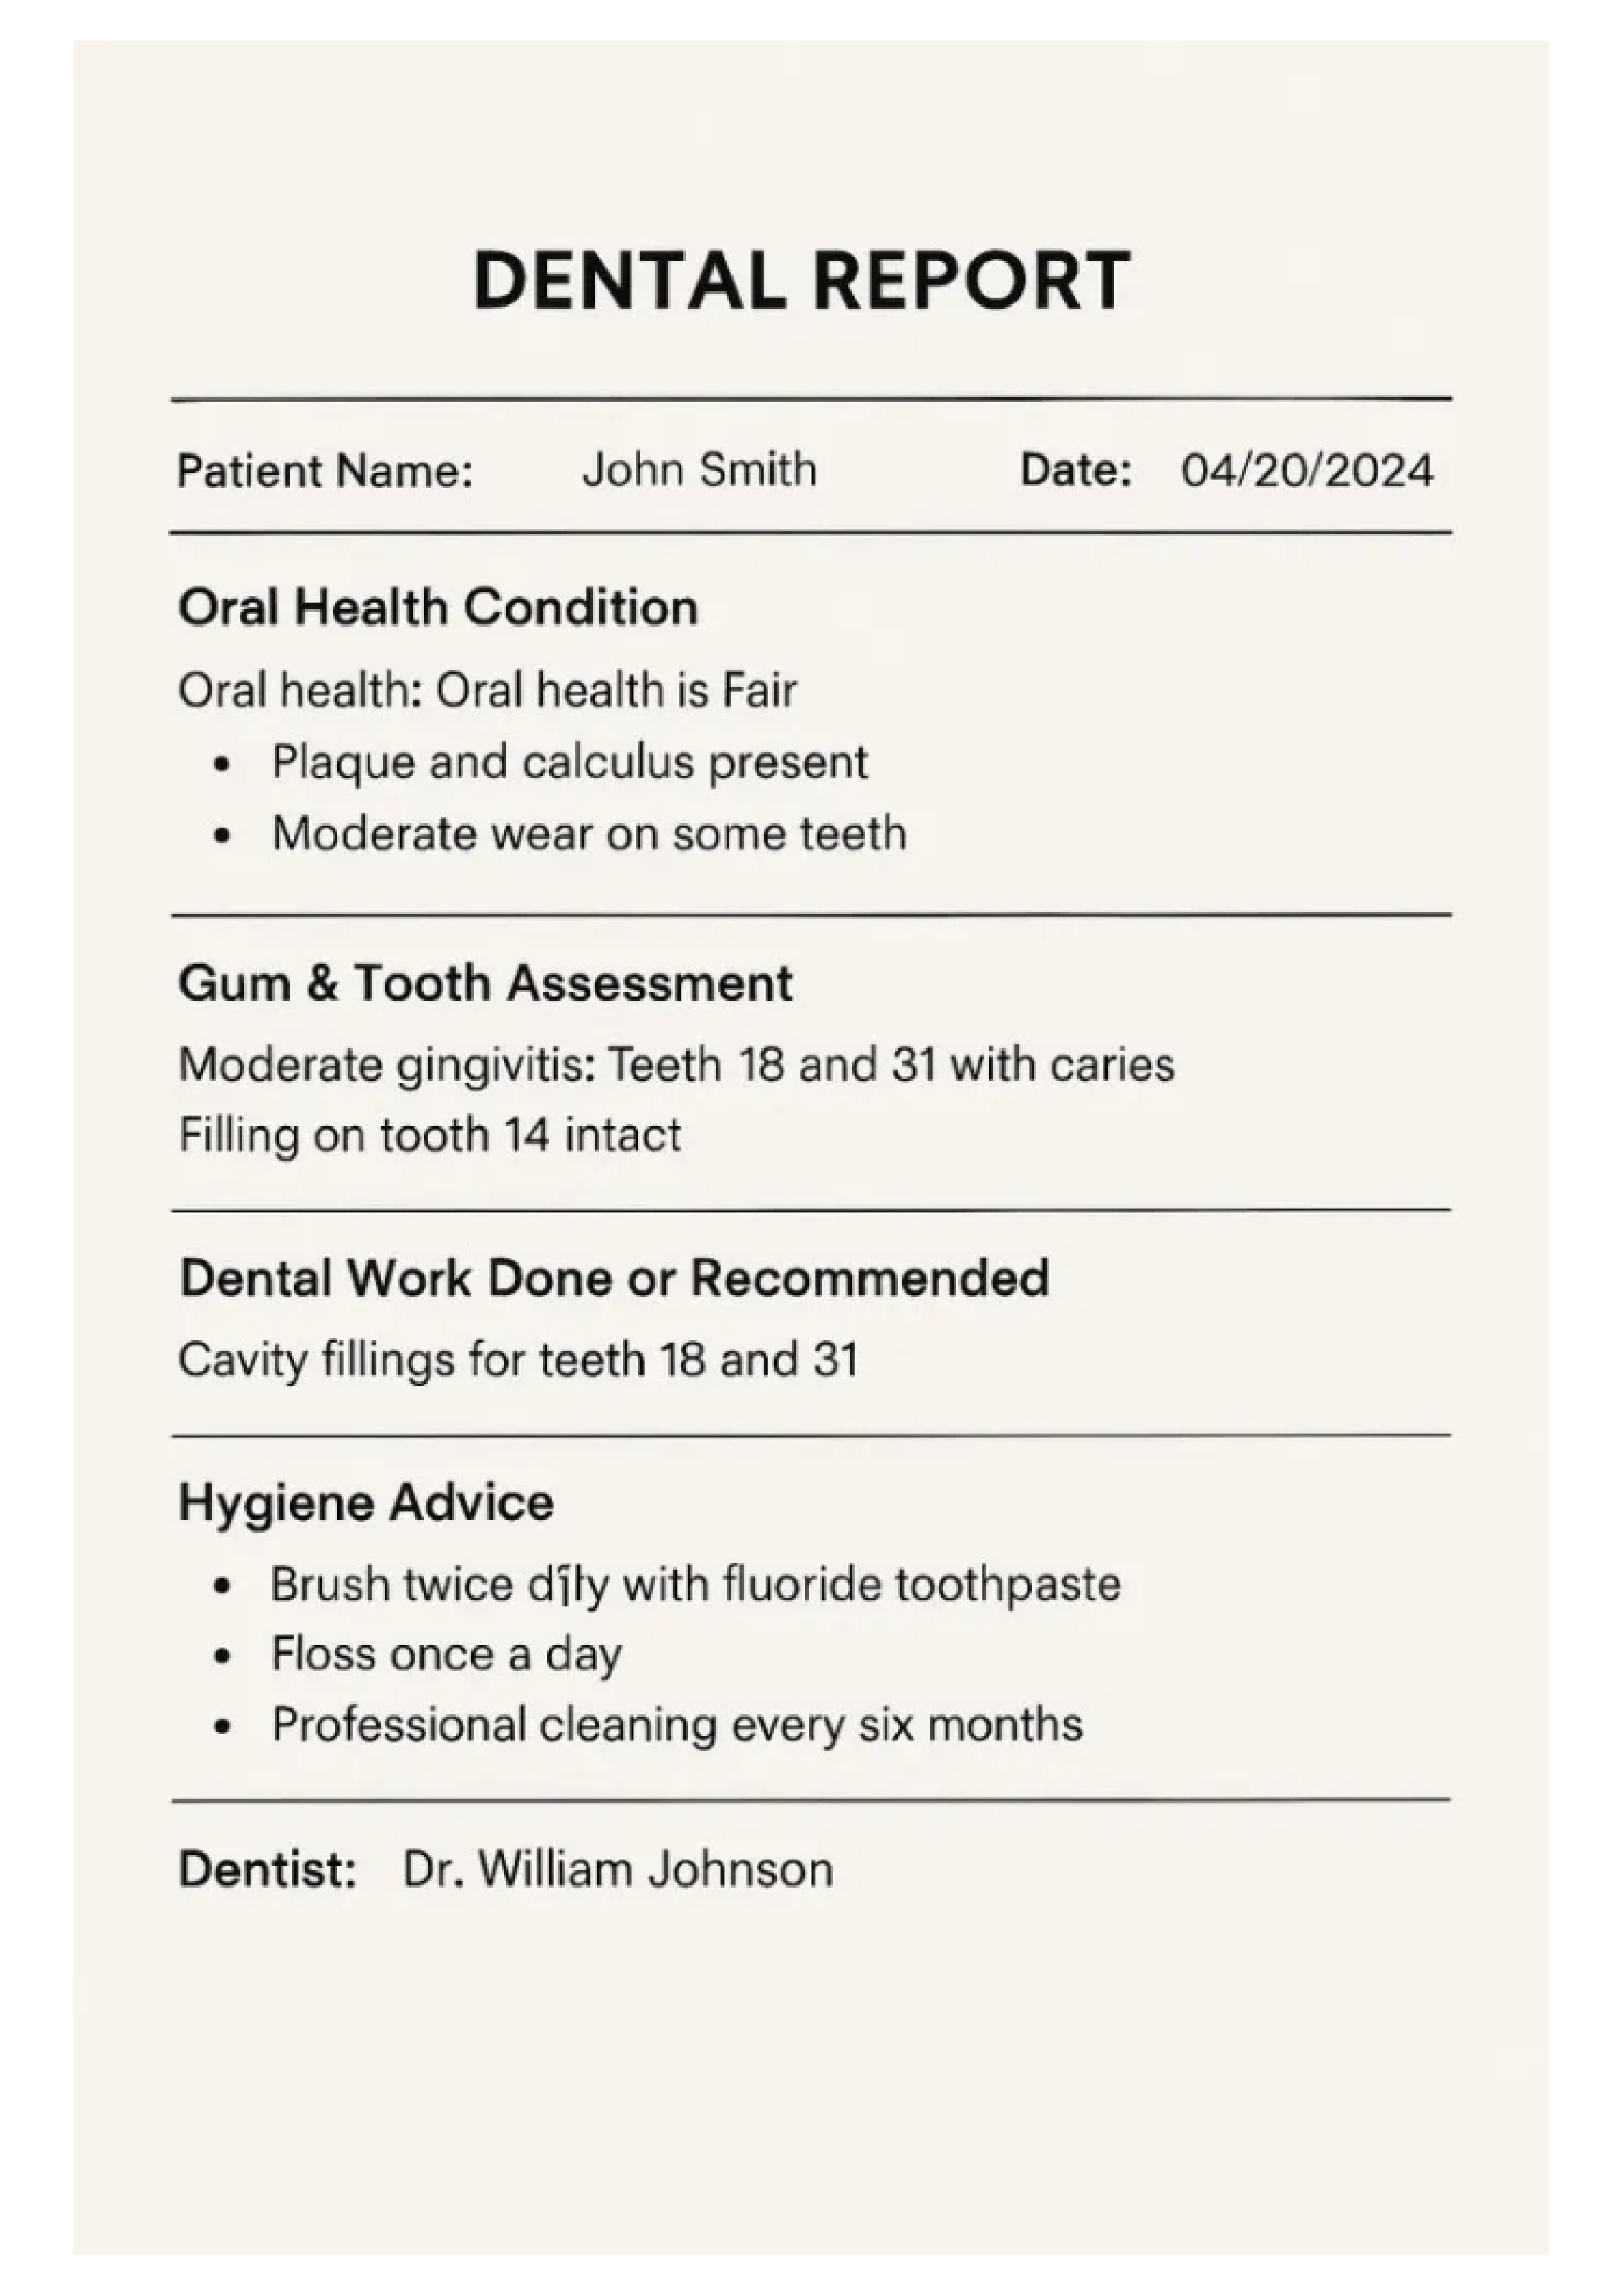

In [19]:
import pymupdf
from PIL import Image
from io import BytesIO
from IPython.display import display

with pymupdf.open(pdf_path) as doc:
    page = doc[0]

    pix = page.get_pixmap(dpi=300)
    image = Image.open(BytesIO(pix.tobytes("png")))

display(image)

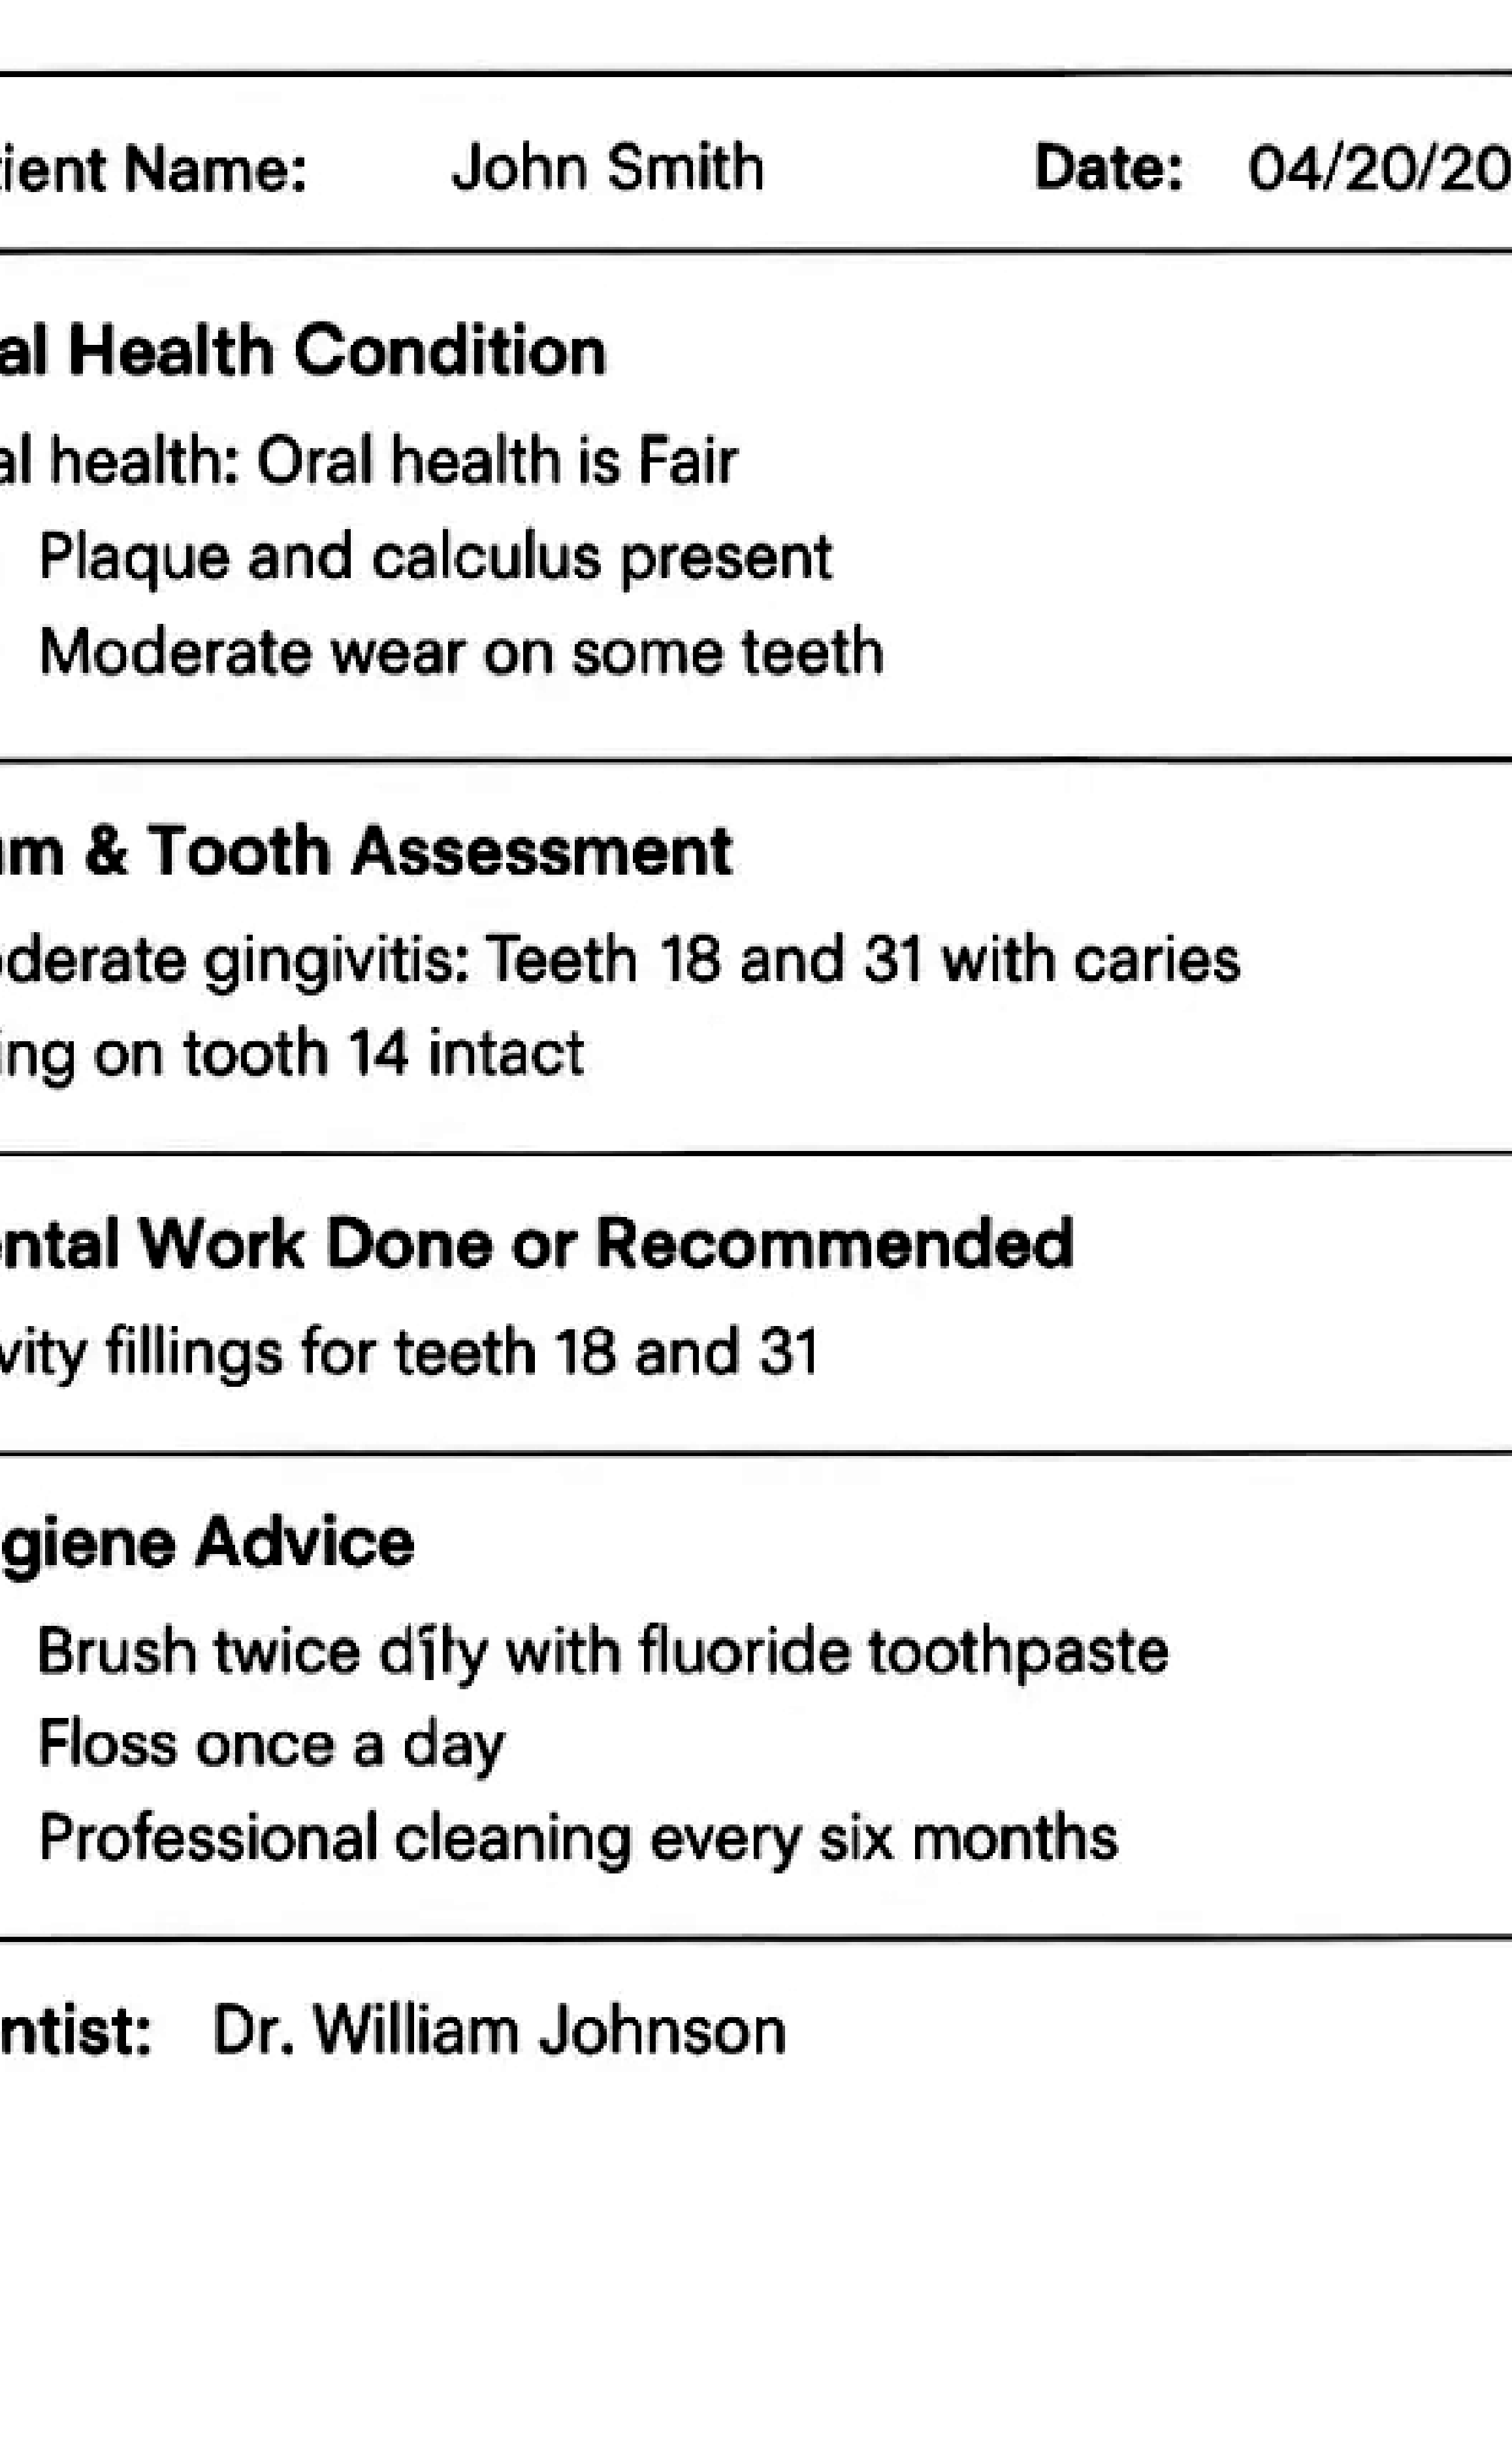


--- Extracted Text ---

ient Name: John Smith Date: 04/20/20
al Health Condition
al health: Oral health is Fair
Plaque and calculus present
Moderate wear on some teeth
im & Tooth Assessment
derate gingivitis: Teeth 18 and 31 with caries
ng on tooth 14 intact
ntal Work Done or Recommended
vity fillings for teeth 18 and 31
giene Advice
Brush twice dijly with fluoride toothpaste
Floss once a day
Professional cleaning every six months
ntist: Dr. William Johnson



In [20]:
import pymupdf
import pytesseract
from PIL import Image, ImageOps, ImageEnhance
from io import BytesIO

with pymupdf.open(pdf_path) as doc:
    page = doc[0]

    pix = page.get_pixmap(dpi=400)
    image = Image.open(BytesIO(pix.tobytes("png")))

    # Crop the main text area of the report
    width, height = image.size

    cropped = image.crop((
        int(width * 0.15),
        int(height * 0.15),
        int(width * 0.85),
        int(height * 0.95)
    ))

    # Improve contrast
    cropped = ImageOps.grayscale(cropped)
    cropped = ImageEnhance.Contrast(cropped).enhance(2)

    # Display the cropped image
    display(cropped)

    # Extract text
    text = pytesseract.image_to_string(
        cropped,
        lang="eng",
        config="--oem 3 --psm 6"
    )

    print("\n--- Extracted Text ---\n")
    print(text)

In [21]:
import re
import json

# Use the OCR output from your previous cell
raw_text = extracted_text

# Report sections to identify
section_names = [
    "Patient Name",
    "Oral Health Condition",
    "Gum & Tooth Assessment",
    "Dental Work Done or Recommended",
    "Hygiene Advice",
    "Dentist"
]

# Initialize structured report
structured_report = {
    "raw_text": raw_text,
    "sections": {}
}

current_section = "General Information"

# Process the OCR text line by line
for line in raw_text.splitlines():

    line = line.strip()

    if not line:
        continue

    # Check whether the line begins a known section
    matched_section = None

    for heading in section_names:
        if line.lower().startswith(heading.lower()):
            matched_section = heading
            break

    if matched_section:
        current_section = matched_section

        if current_section not in structured_report["sections"]:
            structured_report["sections"][current_section] = []

        structured_report["sections"][current_section].append(line)

    else:
        structured_report["sections"].setdefault(
            current_section, []
        ).append(line)

# Display the structured report
print(json.dumps(
    structured_report,
    indent=4,
    ensure_ascii=False
))

{
    "raw_text": "Patient Name: John Smith Date: 04/20/2024\nOral Health Condition\nOral health: Oral health is Fair\n\ne Plaque and calculus present\n\n« Moderate wear on some teeth\nGum & Tooth Assessment\nModerate gingivitis: Teeth 18 and 31 with caries\nFilling on tooth 14 intact\nDental Work Done or Recommended\nCavity fillings for teeth 18 and 31\nHygiene Advice\n\ne Brush twice dijly with fluoride toothpaste\n\ne Floss once a day\n\ne Professional cleaning every six months\nDentist: Dr. William Johnson\n",
    "sections": {
        "Patient Name": [
            "Patient Name: John Smith Date: 04/20/2024"
        ],
        "Oral Health Condition": [
            "Oral Health Condition",
            "Oral health: Oral health is Fair",
            "e Plaque and calculus present",
            "« Moderate wear on some teeth"
        ],
        "Gum & Tooth Assessment": [
            "Gum & Tooth Assessment",
            "Moderate gingivitis: Teeth 18 and 31 with caries",
           

In [22]:
import re
import json

# Use the existing OCR output
raw_text = extracted_text

# Initialize structured fields
report_data = {
    "report_title": None,
    "patient_name": None,
    "report_date": None,
    "oral_health_condition": [],
    "gum_and_tooth_assessment": [],
    "dental_work_recommended": [],
    "hygiene_advice": [],
    "dentist": None,
    "raw_text": raw_text
}

current_section = None

section_map = {
    "oral health condition": "oral_health_condition",
    "gum & tooth assessment": "gum_and_tooth_assessment",
    "dental work done or recommended": "dental_work_recommended",
    "hygiene advice": "hygiene_advice"
}

for line in raw_text.splitlines():
    line = line.strip()

    if not line:
        continue

    # Extract report title
    if line.upper() == "DENTAL REPORT":
        report_data["report_title"] = line
        continue

    # Extract patient name and date
    match = re.search(
        r"Patient Name:\s*(.*?)\s+Date:\s*(\d{2}/\d{2}/\d{4})",
        line,
        re.IGNORECASE
    )

    if match:
        report_data["patient_name"] = match.group(1).strip()
        report_data["report_date"] = match.group(2)
        continue

    # Extract dentist
    match = re.search(
        r"Dentist:\s*(.+)",
        line,
        re.IGNORECASE
    )

    if match:
        report_data["dentist"] = match.group(1).strip()
        continue

    # Identify section headings
    normalized_line = line.lower()

    if normalized_line in section_map:
        current_section = section_map[normalized_line]
        continue

    # Store text under the current section
    if current_section:
        # Remove OCR bullet markers only from structured values
        cleaned_line = re.sub(r"^[e•]\s*", "", line).strip()

        if cleaned_line:
            report_data[current_section].append(cleaned_line)

print(json.dumps(
    report_data,
    indent=4,
    ensure_ascii=False
))

{
    "report_title": null,
    "patient_name": "John Smith",
    "report_date": "04/20/2024",
    "oral_health_condition": [
        "Oral health: Oral health is Fair",
        "Plaque and calculus present",
        "« Moderate wear on some teeth"
    ],
    "gum_and_tooth_assessment": [
        "Moderate gingivitis: Teeth 18 and 31 with caries",
        "Filling on tooth 14 intact"
    ],
    "dental_work_recommended": [
        "Cavity fillings for teeth 18 and 31"
    ],
    "hygiene_advice": [
        "Brush twice dijly with fluoride toothpaste",
        "Floss once a day",
        "Professional cleaning every six months"
    ],
    "dentist": "Dr. William Johnson",
    "raw_text": "Patient Name: John Smith Date: 04/20/2024\nOral Health Condition\nOral health: Oral health is Fair\n\ne Plaque and calculus present\n\n« Moderate wear on some teeth\nGum & Tooth Assessment\nModerate gingivitis: Teeth 18 and 31 with caries\nFilling on tooth 14 intact\nDental Work Done or Recommended\nCa

In [23]:
def create_report_summary(report_data):
    """Create a plain-language summary from the extracted report fields."""

    def format_list(items):
        if not items:
            return "Not mentioned in the report."
        return "\n".join(f"- {item}" for item in items)

    summary = f"""
MEDICAL REPORT SUMMARY

Report: {report_data.get("report_title", "Not specified")}
Patient: {report_data.get("patient_name", "Not specified")}
Date: {report_data.get("report_date", "Not specified")}

1. Reported condition
{format_list(report_data.get("oral_health_condition", []))}

2. Gum and tooth assessment
{format_list(report_data.get("gum_and_tooth_assessment", []))}

3. Work recommended
{format_list(report_data.get("dental_work_recommended", []))}

4. Hygiene advice in the report
{format_list(report_data.get("hygiene_advice", []))}

Dentist: {report_data.get("dentist", "Not specified")}

Note: This summary restates information extracted from the report. It is not a diagnosis.
"""

    # Flag text that may need checking rather than silently correcting it.
    raw_text = report_data.get("raw_text", "").lower()
    if "diy" in raw_text:
        summary += (
            "\n\nText to verify: The extracted report contains “diy” "
            "in the brushing advice. Check the original report for the intended word."
        )

    return summary.strip()

In [24]:
report_summary = create_report_summary(report_data)
print(report_summary)

MEDICAL REPORT SUMMARY

Report: None
Patient: John Smith
Date: 04/20/2024

1. Reported condition
- Oral health: Oral health is Fair
- Plaque and calculus present
- « Moderate wear on some teeth

2. Gum and tooth assessment
- Moderate gingivitis: Teeth 18 and 31 with caries
- Filling on tooth 14 intact

3. Work recommended
- Cavity fillings for teeth 18 and 31

4. Hygiene advice in the report
- Brush twice dijly with fluoride toothpaste
- Floss once a day
- Professional cleaning every six months

Dentist: Dr. William Johnson

Note: This summary restates information extracted from the report. It is not a diagnosis.


In [25]:
test_results = [
    {
        "test_name": "Hemoglobin",
        "value": 10.2,
        "unit": "g/dL",
        "reference_range": "12.0–15.5 g/dL",
        "lab_flag": "Low",
        "source_text": "Hemoglobin 10.2 g/dL (12.0–15.5) Low"
    }
]

In [29]:
def format_lab_result(result):
    name = result.get("test_name", "Unnamed test")
    value = result.get("value")
    unit = result.get("unit", "")
    low = result.get("range_low")
    high = result.get("range_high")
    range_unit = result.get("range_unit", unit)
    lab_flag = result.get("lab_flag")

    lines = [f"Test: {name}", f"Result: {value} {unit}".strip()]

    if low is not None and high is not None:
        lines.append(f"Reference range: {low}–{high} {range_unit}".strip())

        # Compare only when the result and range are numeric and use the same unit.
        if unit == range_unit and isinstance(value, (int, float)):
            if value < low:
                lines.append("Range comparison: Below the stated reference range.")
            elif value > high:
                lines.append("Range comparison: Above the stated reference range.")
            else:
                lines.append("Range comparison: Within the stated reference range.")
        else:
            lines.append("Range comparison: Could not compare safely; check the value and units.")
    else:
        lines.append("Reference range: Not clearly provided in the extracted report.")

    if lab_flag:
        lines.append(f"Report flag: {lab_flag}")

    lines.append(
        "Note: This describes the report's result and reference range; "
        "it is not a diagnosis."
    )

    return "\n".join(lines)


sample_result = {
    "test_name": "Hemoglobin",
    "value": 10.2,
    "unit": "g/dL",
    "range_low": 12.0,
    "range_high": 15.5,
    "range_unit": "g/dL",
    "lab_flag": "Low"
}

print(format_lab_result(sample_result))

Test: Hemoglobin
Result: 10.2 g/dL
Reference range: 12.0–15.5 g/dL
Range comparison: Below the stated reference range.
Report flag: Low
Note: This describes the report's result and reference range; it is not a diagnosis.


In [30]:
import re

def extract_lab_result(text):
    pattern = re.compile(
        r"(?P<test_name>[A-Za-z][A-Za-z /()-]*)\s*[:\-]\s*"
        r"(?P<value>\d+(?:\.\d+)?)\s*(?P<unit>[A-Za-z/]+)\s*"
        r"(?:\(?\s*(?P<range_low>\d+(?:\.\d+)?)\s*[-–]\s*"
        r"(?P<range_high>\d+(?:\.\d+)?)\s*(?P<range_unit>[A-Za-z/]+)?\s*\)?)?"
        r"(?:\s*(?P<lab_flag>Low|High|Normal))?",
        re.IGNORECASE
    )

    match = pattern.search(text)
    if not match:
        return None

    data = match.groupdict()
    data["value"] = float(data["value"])
    data["range_low"] = float(data["range_low"]) if data["range_low"] else None
    data["range_high"] = float(data["range_high"]) if data["range_high"] else None
    data["range_unit"] = data["range_unit"] or data["unit"]
    return data


sample_text = "Hemoglobin: 10.2 g/dL (12.0-15.5 g/dL) Low"
extracted = extract_lab_result(sample_text)

print(extracted)
if extracted:
    print()
    print(format_lab_result(extracted))

{'test_name': 'Hemoglobin', 'value': 10.2, 'unit': 'g/dL', 'range_low': 12.0, 'range_high': 15.5, 'range_unit': 'g/dL', 'lab_flag': 'Low'}

Test: Hemoglobin
Result: 10.2 g/dL
Reference range: 12.0–15.5 g/dL
Range comparison: Below the stated reference range.
Report flag: Low
Note: This describes the report's result and reference range; it is not a diagnosis.


In [31]:
def extract_lab_results(text):
    pattern = re.compile(
        r"(?P<test_name>[A-Za-z][A-Za-z /()-]*)\s*[:\-]\s*"
        r"(?P<value>\d+(?:\.\d+)?)\s*(?P<unit>[A-Za-z/]+)\s*"
        r"(?:\(?\s*(?P<range_low>\d+(?:\.\d+)?)\s*[-–]\s*"
        r"(?P<range_high>\d+(?:\.\d+)?)\s*(?P<range_unit>[A-Za-z/]+)?\s*\)?)?"
        r"(?:\s*(?P<lab_flag>Low|High|Normal))?",
        re.IGNORECASE
    )

    results = []

    for match in pattern.finditer(text):
        data = match.groupdict()
        data["value"] = float(data["value"])
        data["range_low"] = float(data["range_low"]) if data["range_low"] else None
        data["range_high"] = float(data["range_high"]) if data["range_high"] else None
        data["range_unit"] = data["range_unit"] or data["unit"]

        results.append(data)

    return results

In [32]:
sample_text = """
Hemoglobin: 10.2 g/dL (12.0-15.5 g/dL) Low
Glucose: 95 mg/dL (70-99 mg/dL) Normal
"""

results = extract_lab_results(sample_text)

for result in results:
    print(format_lab_result(result))
    print("-" * 40)

Test: Hemoglobin
Result: 10.2 g/dL
Reference range: 12.0–15.5 g/dL
Range comparison: Below the stated reference range.
Report flag: Low
Note: This describes the report's result and reference range; it is not a diagnosis.
----------------------------------------
Test: Glucose
Result: 95.0 mg/dL
Reference range: 70.0–99.0 mg/dL
Range comparison: Within the stated reference range.
Report flag: Normal
Note: This describes the report's result and reference range; it is not a diagnosis.
----------------------------------------


In [33]:
print(ocr_text)

NameError: name 'ocr_text' is not defined

In [34]:
%whos

Variable                  Type              Data/Info
-----------------------------------------------------
BytesIO                   type              <class '_io.BytesIO'>
GROQ_API_KEY              str               gsk_sEA8PAC3VcmM7Dcg47ofW<...>YM97rd1aVjsk5IrhxCfnMVyaW
GROQ_MODEL                str               openai/gpt-oss-120b
Groq                      type              <class 'groq.Groq'>
Image                     module            <module 'PIL.Image' from <...>packages\\PIL\\Image.py'>
ImageEnhance              module            <module 'PIL.ImageEnhance<...>s\\PIL\\ImageEnhance.py'>
ImageOps                  module            <module 'PIL.ImageOps' fr<...>kages\\PIL\\ImageOps.py'>
Path                      type              <class 'pathlib.Path'>
build_report_prompt       function          <function build_report_pr<...>pt at 0x0000026A51F0FE20>
cleaned_line              str               Professional cleaning every six months
config                    str               --oe

In [35]:
print(report_data["raw_text"])

Patient Name: John Smith Date: 04/20/2024
Oral Health Condition
Oral health: Oral health is Fair

e Plaque and calculus present

« Moderate wear on some teeth
Gum & Tooth Assessment
Moderate gingivitis: Teeth 18 and 31 with caries
Filling on tooth 14 intact
Dental Work Done or Recommended
Cavity fillings for teeth 18 and 31
Hygiene Advice

e Brush twice dijly with fluoride toothpaste

e Floss once a day

e Professional cleaning every six months
Dentist: Dr. William Johnson



In [ ]:
print(extracted_text)

In [36]:
print(report_data["raw_text"])
print("\n--- Structured report ---")
print(report_data)

Patient Name: John Smith Date: 04/20/2024
Oral Health Condition
Oral health: Oral health is Fair

e Plaque and calculus present

« Moderate wear on some teeth
Gum & Tooth Assessment
Moderate gingivitis: Teeth 18 and 31 with caries
Filling on tooth 14 intact
Dental Work Done or Recommended
Cavity fillings for teeth 18 and 31
Hygiene Advice

e Brush twice dijly with fluoride toothpaste

e Floss once a day

e Professional cleaning every six months
Dentist: Dr. William Johnson


--- Structured report ---
{'report_title': None, 'patient_name': 'John Smith', 'report_date': '04/20/2024', 'oral_health_condition': ['Oral health: Oral health is Fair', 'Plaque and calculus present', '« Moderate wear on some teeth'], 'gum_and_tooth_assessment': ['Moderate gingivitis: Teeth 18 and 31 with caries', 'Filling on tooth 14 intact'], 'dental_work_recommended': ['Cavity fillings for teeth 18 and 31'], 'hygiene_advice': ['Brush twice dijly with fluoride toothpaste', 'Floss once a day', 'Professional cleani

In [38]:
import json

def build_report_prompt(report_data):
    # Send only report content needed for the summary.
    # Keep patient identifiers out of the prompt.
    safe_report = {
        key: value
        for key, value in report_data.items()
        if key not in {"patient_name", "dentist", "raw_text"}
    }

    report_json = json.dumps(safe_report, ensure_ascii=False, indent=2)

    prompt = f"""
You explain medical reports in simple language for a general reader.

Use only the information in the report data below.
Do not diagnose, guess missing information, add medical facts,
or recommend treatment that is not written in the report.

Keep medical findings, numbers, tooth numbers, and recommendations accurate.
Separate findings from recommendations.
If wording is unclear, mark it for verification instead of guessing.

Return these sections:
1. Plain-language summary
2. Findings mentioned in the report
3. Recommendations written in the report
4. Text that needs verification

Report data:
{report_json}
"""
    return prompt

report_prompt = build_report_prompt(report_data)

print(report_prompt)


You explain medical reports in simple language for a general reader.

Use only the information in the report data below.
Do not diagnose, guess missing information, add medical facts,
or recommend treatment that is not written in the report.

Keep medical findings, numbers, tooth numbers, and recommendations accurate.
Separate findings from recommendations.
If wording is unclear, mark it for verification instead of guessing.

Return these sections:
1. Plain-language summary
2. Findings mentioned in the report
3. Recommendations written in the report
4. Text that needs verification

Report data:
{
  "report_title": null,
  "report_date": "04/20/2024",
  "oral_health_condition": [
    "Oral health: Oral health is Fair",
    "Plaque and calculus present",
    "« Moderate wear on some teeth"
  ],
  "gum_and_tooth_assessment": [
    "Moderate gingivitis: Teeth 18 and 31 with caries",
    "Filling on tooth 14 intact"
  ],
  "dental_work_recommended": [
    "Cavity fillings for teeth 18 and 

In [ ]:
%pip install -U google-genai

In [ ]:
from getpass import getpass
from google import genai

api_key = getpass("Enter your Gemini API key: ")
client = genai.Client(api_key=api_key)

In [39]:
def generate_report_summary(report_data):
    prompt = build_report_prompt(report_data)

    response = client.models.generate_content(
        model="gemini-3.8-flash",
        contents=prompt
    )

    return response.text


plain_language_summary = generate_report_summary(report_data)
print(plain_language_summary)

NameError: name 'client' is not defined

In [40]:
response = client.models.generate_content(
    model="gemini-3.7-flash",
    contents="Reply with exactly: HEALIX connection successful"
)

print(response.text)

NameError: name 'client' is not defined

In [41]:
response = client.models.generate_content(
    model="gemini-3.6-flash",
    contents="Reply with exactly: HEALIX connection successful"
)
print(response.text)

NameError: name 'client' is not defined

In [ ]:
import json
from google.genai.errors import ServerError

def generate_report_summary(report_data):
    prompt = build_report_prompt(report_data)

    try:
        response = client.models.generate_content(
            model="gemini-3.8-flash",
            contents=prompt
        )

        if response.text:
            return response.text

        raise ValueError("Gemini returned an empty response.")

    except ServerError as e:
        if getattr(e, "code", None) != 503:
            raise

        return (
            "AI summary is temporarily unavailable because Gemini returned "
            "503 UNAVAILABLE.\n\n"
            "Extracted report data (shown as recorded, not interpreted):\n"
            + json.dumps(report_data, indent=2, ensure_ascii=False, default=str)
        )

plain_language_summary = generate_report_summary(report_data)
print(plain_language_summary)

In [ ]:
def format_report_fallback(report_data):
    def show_list(title, items):
        lines = [f"\n{title}"]
        lines.extend(f"• {item}" for item in items)
        return "\n".join(lines)

    summary = [
        "DENTAL REPORT",
        f"Patient: {report_data.get('patient_name', 'Not provided')}",
        f"Report date: {report_data.get('report_date', 'Not provided')}",
    ]

    summary.append(show_list(
        "Oral Health Condition",
        report_data.get("oral_health_condition", [])
    ))
    summary.append(show_list(
        "Gum & Tooth Assessment",
        report_data.get("gum_and_tooth_assessment", [])
    ))
    summary.append(show_list(
        "Dental Work Done or Recommended",
        report_data.get("dental_work_recommended", [])
    ))
    summary.append(show_list(
        "Hygiene Advice",
        report_data.get("hygiene_advice", [])
    ))

    summary.extend([
        f"\nDentist: {report_data.get('dentist', 'Not provided')}",
        '\nReview note: The extracted phrase "Brush twice diy" is unclear. '
        "Check it against the original report.",
        "\nNotice: This is a formatted display of extracted report text, "
        "not an AI-generated interpretation or diagnosis."
    ])

    return "\n".join(summary)

formatted_report = format_report_fallback(report_data)
print(formatted_report)

In [ ]:

from google.genai.errors import ServerError

def generate_report_summary(report_data):
    prompt = build_report_prompt(report_data)

    try:
        response = client.models.generate_content(
            model="gemini-3.8-flash",
            contents=prompt
        )

        if response.text:
            return response.text

        return format_report_fallback(report_data)

    except ServerError as e:
        if getattr(e, "code", None) == 503:
            return format_report_fallback(report_data)
        raise

In [ ]:
plain_language_summary = generate_report_summary(report_data)
print(plain_language_summary)

In [ ]:
from google.genai.errors import ServerError

def format_report_fallback(report_data):
    sections = [
        "DENTAL REPORT",
        f"Patient: {report_data.get('patient_name', 'Not provided')}",
        f"Report date: {report_data.get('report_date', 'Not provided')}",
    ]

    for heading, key in [
        ("Oral Health Condition", "oral_health_condition"),
        ("Gum & Tooth Assessment", "gum_and_tooth_assessment"),
        ("Dental Work Done or Recommended", "dental_work_recommended"),
        ("Hygiene Advice", "hygiene_advice"),
    ]:
        sections.append(f"\n{heading}")
        sections.extend(f"• {item}" for item in report_data.get(key, []))

    sections.extend([
        f"\nDentist: {report_data.get('dentist', 'Not provided')}",
        '\nReview note: The phrase "Brush twice diy" is unclear. Check it against the original report.',
        "\nNotice: This is extracted report text, not an AI-generated interpretation or diagnosis."
    ])

    return "\n".join(sections)


def generate_report_summary(report_data):
    prompt = build_report_prompt(report_data)

    try:
        response = client.models.generate_content(
            model="gemini-3.8-flash",
            contents=prompt
        )
        if response.text:
            return response.text
        return format_report_fallback(report_data)

    except ServerError as e:
        if getattr(e, "code", None) == 503:
            return format_report_fallback(report_data)
        raise

In [ ]:
print(format_report_fallback(report_data))

In [ ]:
print(format_report_fallback(report_data))

In [ ]:
def format_report_fallback(report_data):
    sections = [
        "DENTAL REPORT",
        f"Patient: {report_data.get('patient_name', 'Not provided')}",
        f"Report date: {report_data.get('report_date', 'Not provided')}",
    ]

    for heading, key in [
        ("Oral Health Condition", "oral_health_condition"),
        ("Gum & Tooth Assessment", "gum_and_tooth_assessment"),
        ("Dental Work Done or Recommended", "dental_work_recommended"),
        ("Hygiene Advice", "hygiene_advice"),
    ]:
        sections.append(f"\n{heading}")
        sections.extend(f"• {item}" for item in report_data.get(key, []))

    sections.extend([
        f"\nDentist: {report_data.get('dentist', 'Not provided')}",
        '\nReview note: "Brush twice diy" is unclear. Check the original report.',
        "\nNotice: Extracted report text only, not an AI-generated interpretation or diagnosis."
    ])

    return "\n".join(sections)

print(format_report_fallback(report_data))

In [ ]:


report_data = {
    "report_title": "DENTAL REPORT",
    "patient_name": "John Smith",
    "report_date": "04/20/2024",
    "oral_health_condition": [
        "Oral health: Oral health is Fair",
        "Plaque and calculus present",
        "Moderate wear on some teeth"
    ],
    "gum_and_tooth_assessment": [
        "Moderate gingivitis: Teeth 18 and 31 with caries",
        "Filling on tooth 14 intact"
    ],
    "dental_work_recommended": [
        "Cavity fillings for teeth 18 and 31"
    ],
    "hygiene_advice": [
        "Brush twice diy with fluoride toothpaste",
        "Floss once a day",
        "Professional cleaning every six months"
    ],
    "dentist": "Dr. William Johnson"
}

print(format_report_fallback(report_data))

In [ ]:
print(format_report_fallback(report_data))

In [ ]:
print(report_data)

In [ ]:
import json

def format_report_fallback(report_data):
    """Create a readable summary locally when Gemini is unavailable."""
    sections = [
        ("Oral Health Condition", "oral_health_condition"),
        ("Gum and Tooth Assessment", "gum_and_tooth_assessment"),
        ("Dental Work Recommended", "dental_work_recommended"),
        ("Hygiene Advice", "hygiene_advice"),
    ]

    lines = [
        f"Report: {report_data.get('report_title', 'Medical Report')}",
        f"Patient: {report_data.get('patient_name', 'Not provided')}",
        f"Date: {report_data.get('report_date', 'Not provided')}",
        f"Dentist/Doctor: {report_data.get('dentist', 'Not provided')}",
    ]

    for heading, key in sections:
        values = report_data.get(key, [])
        if values:
            lines.append(f"\n{heading}:")
            lines.extend(f"- {item}" for item in values)

    return "\n".join(lines)


def generate_report_summary(report_data):
    """Try Gemini; return None if the service is unavailable."""
    try:
        prompt = build_report_prompt(report_data)

        response = client.models.generate_content(
            model=GEMINI_MODEL,  # Set this to the model name you already tested
            contents=prompt
        )

        summary = getattr(response, "text", None)
        return summary.strip() if summary else None

    except Exception as error:
        print("Gemini summary unavailable:", error)
        return None


def process_report_data(report_data):
    """
    Combine extracted report data and optional Gemini summary.
    Call this after your existing PDF extraction creates report_data.
    """
    ai_summary = generate_report_summary(report_data)

    if ai_summary:
        summary_status = "success"
        message = "Report extracted and AI summary generated."
    else:
        summary_status = "unavailable"
        message = "Report extracted. AI summary is temporarily unavailable."

    return {
        "status": "success",
        "report_data": report_data,
        "ai_summary": ai_summary,
        "summary_status": summary_status,
        "fallback_summary": format_report_fallback(report_data),
        "message": message
    }

In [ ]:
result = process_report_data(report_data)

print(json.dumps(result, indent=2, ensure_ascii=False))

In [ ]:
def build_report_prompt(report_data):
    report_text = json.dumps(
        report_data,
        indent=2,
        ensure_ascii=False
    )

    return f"""
You are helping summarize a medical report.

Summarize only the information present in the report data below.
Do not diagnose, add new medical facts, or invent recommendations.
Keep the summary clear and easy for a patient to understand.
If any wording appears unclear or possibly misread by OCR, flag it for verification.

Report data:
{report_text}
"""

In [ ]:
GEMINI_MODEL = "gemini-3.8-flash"

In [ ]:
result = process_report_data(report_data)

print("Summary status:", result["summary_status"])
print("AI summary:", result["ai_summary"])
print("Fallback summary:", result["fallback_summary"])

In [ ]:
from google import genai
from getpass import getpass

client = genai.Client(api_key=getpass("Enter your Gemini API key: "))

In [ ]:
from google import genai, types
from getpass import getpass

client = genai.Client(
    api_key=getpass("Enter your Gemini API key: "),
    http_options=types.HttpOptions(timeout=30000)  # 30 seconds
)



In [ ]:
def generate_report_summary(report_data):
    try:
        prompt = build_report_prompt(report_data)

        response = client.models.generate_content(
            model=GEMINI_MODEL,
            contents=prompt
        )

        summary = getattr(response, "text", None)
        return summary.strip() if summary else None

    except Exception as error:
        print("Gemini summary unavailable:", error)
        return None

In [ ]:
result = process_report_data(report_data)
print("Summary status:", result["summary_status"])
print("AI summary:", result["ai_summary"])

In [ ]:
result = {
    "status": "success",
    "report_data": report_data,
    "ai_summary": None,
    "summary_status": "not_requested",
    "fallback_summary": format_report_fallback(report_data),
    "message": "Report extracted successfully."
}

print(result["fallback_summary"])

In [ ]:
result = process_report_data(report_data)

print("Status:", result["status"])
print("Summary status:", result["summary_status"])
print("AI summary:", result["ai_summary"])
print("Fallback summary:", result["fallback_summary"])

In [ ]:
from pathlib import Path
import pytesseract

tesseract_path = Path(
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

print("Tesseract exists:", tesseract_path.exists())

if tesseract_path.exists():
    pytesseract.pytesseract.tesseract_cmd = str(tesseract_path)
    print("Tesseract version:", pytesseract.get_tesseract_version())


In [ ]:
from pathlib import Path
from io import BytesIO

import pymupdf
import pytesseract
from PIL import Image, ImageOps

pytesseract.pytesseract.tesseract_cmd = (
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)

pdf_path = Path(
    r"C:\Users\mohammad rayyan\HEALIX\HEALIX\DATA\report.pdf"
)

pages_text = []

with pymupdf.open(pdf_path) as doc:
    for page_number, page in enumerate(doc, start=1):

        text = page.get_text("text").strip()

        # Use OCR when the PDF has no readable embedded text
        if len(text) < 30:
            pix = page.get_pixmap(dpi=350, alpha=False)
            image = Image.open(
                BytesIO(pix.tobytes("png"))
            ).convert("L")

            image = ImageOps.autocontrast(image)

            text = pytesseract.image_to_string(
                image,
                lang="eng",
                config="--oem 3 --psm 6"
            )

        pages_text.append(text.strip())

ocr_text = "\n\n".join(pages_text)

print("Pages processed:", len(pages_text))
print("Extracted characters:", len(ocr_text))
print("\n--- EXTRACTED REPORT TEXT ---\n")
print(ocr_text)

In [ ]:
from pathlib import Path
from io import BytesIO

import pymupdf
import pytesseract

from PIL import Image, ImageOps


TESSERACT_PATH = Path(
    r"C:\Program Files\Tesseract-OCR\tesseract.exe"
)


def extract_pdf_text(pdf_path, dpi=350, min_text_chars=30):

    # Configure Tesseract every time the function is called
    if not TESSERACT_PATH.is_file():
        raise FileNotFoundError(
            f"Tesseract executable not found: {TESSERACT_PATH}"
        )

    pytesseract.pytesseract.tesseract_cmd = str(TESSERACT_PATH)

    pdf_path = Path(pdf_path)

    if not pdf_path.is_file():
        raise FileNotFoundError(f"PDF not found: {pdf_path}")

    pages_text = []
    extraction_methods = []

    with pymupdf.open(pdf_path) as doc:

        for page_number, page in enumerate(doc, start=1):

            text = page.get_text("text").strip()

            if len(text) >= min_text_chars:
                method = "PDF_TEXT"

            else:
                pix = page.get_pixmap(dpi=dpi, alpha=False)

                image = Image.open(
                    BytesIO(pix.tobytes("png"))
                ).convert("L")

                image = ImageOps.autocontrast(image)

                text = pytesseract.image_to_string(
                    image,
                    lang="eng",
                    config="--oem 3 --psm 6"
                )

                method = "OCR"

            pages_text.append(text.strip())
            extraction_methods.append(method)

    extracted_text = "\n\n".join(pages_text)

    return {
        "text": extracted_text,
        "total_pages": len(pages_text),
        "total_characters": len(extracted_text),
        "methods": extraction_methods
    }

In [ ]:
result = extract_pdf_text(
    r"C:\Users\mohammad rayyan\HEALIX\HEALIX\DATA\report.pdf"
)

print("Pages:", result["total_pages"])
print("Characters:", result["total_characters"])
print("Methods:", result["methods"])

print("\nExtracted text:\n")
print(result["text"])

In [ ]:
import re


def parse_report_data(text):

    def get_section(start, end):
        pattern = (
            re.escape(start)
            + r"(.*?)"
            + r"(?=" + re.escape(end) + r"|$)"
        )

        match = re.search(pattern, text, re.IGNORECASE | re.DOTALL)

        if not match:
            return []

        lines = match.group(1).splitlines()
        items = []

        for line in lines:
            line = line.strip()

            if not line:
                continue

            # Remove OCR bullet characters
            line = re.sub(r"^(?:[•●▪◦]|\be)\s*", "", line)

            items.append(line.strip())

        return items

    patient_match = re.search(
        r"Patient\s*Name\s*:\s*(.*?)\s+Date\s*:\s*"
        r"([\d]{1,2}/[\d]{1,2}/[\d]{4})",
        text,
        re.IGNORECASE
    )

    dentist_match = re.search(
        r"Dentist\s*:\s*(.+)",
        text,
        re.IGNORECASE
    )

    title_match = re.search(
        r"(?im)^\s*(DENTAL REPORT)\s*$",
        text
    )

    report_data = {
        "report_title": title_match.group(1) if title_match else None,
        "patient_name": patient_match.group(1).strip() if patient_match else None,
        "report_date": patient_match.group(2) if patient_match else None,

        "oral_health_condition": get_section(
            "Oral Health Condition",
            "Gum & Tooth Assessment"
        ),

        "gum_and_tooth_assessment": get_section(
            "Gum & Tooth Assessment",
            "Dental Work Done or Recommended"
        ),

        "dental_work_recommended": get_section(
            "Dental Work Done or Recommended",
            "Hygiene Advice"
        ),

        "hygiene_advice": get_section(
            "Hygiene Advice",
            "Dentist:"
        ),

        "dentist": dentist_match.group(1).strip() if dentist_match else None
    }

    return report_data

In [ ]:
result = extract_pdf_text(
    r"C:\Users\mohammad rayyan\HEALIX\HEALIX\DATA\report.pdf"
)

report_data = parse_report_data(result["text"])

from pprint import pprint

pprint(report_data, sort_dicts=False)

In [ ]:
{
    "report_title": None,
    "patient_name": "John Smith",
    "report_date": "04/20/2024",

    "oral_health_condition": [
        "Oral health: Oral health is Fair",
        "Plaque and calculus present",
        "Moderate wear on some teeth"
    ],

    "gum_and_tooth_assessment": [
        "Moderate gingivitis: Teeth 18 and 31 with caries",
        "Filling on tooth 14 intact"
    ],

    "dental_work_recommended": [
        "Cavity fillings for teeth 18 and 31"
    ],

    "hygiene_advice": [
        "Brush twice djly with fluoride toothpaste",
        "Floss once a day",
        "Professional cleaning every six months"
    ],

    "dentist": "Dr. William Johnson"
}

In [ ]:
import json

def build_report_prompt(report_data):

    # Exclude patient-identifying information
    safe_report = {
        key: value
        for key, value in report_data.items()
        if key not in {"patient_name", "dentist", "raw_text"}
    }

    report_json = json.dumps(
        safe_report,
        indent=2,
        ensure_ascii=False
    )

    return f"""
You explain medical reports in simple language.

Use ONLY the information provided below.
Do not diagnose or invent medical facts.
Do not add recommendations absent from the report.
Preserve medical findings and numerical values.
Flag unclear OCR text for verification.

Return:
1. Plain-language summary
2. Findings mentioned in the report
3. Recommendations in the report
4. Text requiring verification

Report:
{report_json}
"""

In [ ]:
final_result = process_report_data(report_data)

print("Status:", final_result["status"])
print("Summary status:", final_result["summary_status"])

print("\n--- GEMINI SUMMARY ---")
print(final_result["ai_summary"])

print("\n--- LOCAL FALLBACK ---")
print(final_result["fallback_summary"])

In [ ]:
def process_report_data(report_data):

    fallback_summary = format_report_fallback(report_data)

    try:
        ai_summary = generate_report_summary(report_data)
    except Exception as error:
        print("Gemini summary unavailable:", error)
        ai_summary = None

    if ai_summary:
        summary_status = "success"
        message = "Report extracted and AI summary generated."
    else:
        summary_status = "unavailable"
        message = "Report extracted. Showing local fallback summary."

    return {
        "status": "success",
        "report_data": report_data,
        "ai_summary": ai_summary,
        "summary_status": summary_status,
        "fallback_summary": fallback_summary,
        "message": message
    }

In [ ]:
final_result = process_report_data(report_data)

print("Status:", final_result["status"])
print("Summary status:", final_result["summary_status"])

print("\n--- GEMINI SUMMARY ---")
print(final_result["ai_summary"])

print("\n--- LOCAL FALLBACK ---")
print(final_result["fallback_summary"])

In [ ]:
def process_report_data(report_data):

    # Always prepare the local fallback
    fallback_summary = format_report_fallback(report_data)

    # Always attempt Gemini
    ai_summary = generate_report_summary(report_data)

    if ai_summary:
        summary_status = "success"
        message = "AI summary generated successfully."

    else:
        summary_status = "fallback"
        message = "Gemini unavailable. Local report summary provided."

    return {
        "status": "success",
        "report_data": report_data,
        "ai_summary": ai_summary,
        "summary_status": summary_status,
        "fallback_summary": fallback_summary,
        "final_summary": ai_summary if ai_summary else fallback_summary,
        "message": message
    }

In [ ]:
print(format_report_fallback(report_data))

In [ ]:
final_result = process_report_data(report_data)

print("Status:", final_result["status"])
print("Summary status:", final_result["summary_status"])

print("\n--- GEMINI SUMMARY ---")
print(final_result["ai_summary"])

print("\n--- LOCAL FALLBACK ---")
print(final_result["fallback_summary"])

In [ ]:
def generate_report_summary(report_data):
    try:
        prompt = build_report_prompt(report_data)

        response = client.models.generate_content(
            model=GEMINI_MODEL,
            contents=prompt
        )

        summary = getattr(response, "text", None)

        return summary.strip() if summary else None

    except Exception as error:
        print("Gemini unavailable:", error)
        return None

In [ ]:
final_result = process_report_data(report_data)

print("Status:", final_result["status"])
print("Summary status:", final_result["summary_status"])
print("Message:", final_result["message"])

print("\n--- FINAL SUMMARY FOR USER ---")
print(final_result["final_summary"])

In [ ]:
GEMINI_MODEL = "gemini-3.8-flash"

print("Gemini model configured:", GEMINI_MODEL)

In [ ]:
final_result = process_report_data(report_data)

print("Status:", final_result["status"])
print("Summary status:", final_result["summary_status"])
print("Message:", final_result["message"])

print("\n--- FINAL SUMMARY ---")
print(final_result["final_summary"])

In [ ]:
def process_pdf_report(pdf_path):

    # 1. Extract PDF text using PyMuPDF/OCR
    extraction = extract_pdf_text(pdf_path)

    if not extraction["text"].strip():
        raise ValueError("No readable text found in the PDF.")

    # 2. Convert extracted text into structured data
    report_data = parse_report_data(extraction["text"])

    # Preserve original OCR text for verification
    report_data["raw_text"] = extraction["text"]

    # 3. Generate Gemini summary or automatic fallback
    response = process_report_data(report_data)

    # 4. Include extraction information
    response["extraction_metadata"] = {
        "total_pages": extraction["total_pages"],
        "total_characters": extraction["total_characters"],
        "methods": extraction["methods"]
    }

    return response

In [ ]:
complete_result = process_pdf_report(
    r"C:\Users\mohammad rayyan\HEALIX\HEALIX\DATA\report.pdf"
)

print("Status:", complete_result["status"])
print("Summary:", complete_result["summary_status"])
print("Extraction:", complete_result["extraction_metadata"])

print("\nFINAL REPORT:\n")
print(complete_result["final_summary"])

In [ ]:
%pip install -U groq

In [62]:
from groq import Groq
from getpass import getpass

GROQ_API_KEY = getpass("Enter your Groq API key: ")

groq_client = Groq(
    api_key=GROQ_API_KEY
)

GROQ_MODEL = "openai/gpt-oss-120b"

print("HEALIX Groq client configured!")

Enter your Groq API key:  ········


HEALIX Groq client configured!


In [ ]:
response = groq_client.chat.completions.create(
    model=GROQ_MODEL,
    messages=[
        {
            "role": "user",
            "content": "Reply exactly: HEALIX Groq connection successful"
        }
    ],
    temperature=0.2
)

print(response.choices[0].message.content)

In [ ]:
import json

def build_report_prompt(report_data):

    allowed_fields = [
        "report_title",
        "report_date",
        "oral_health_condition",
        "gum_and_tooth_assessment",
        "dental_work_recommended",
        "hygiene_advice",
        "test_results",
        "lab_results"
    ]

    safe_report = {
        key: report_data[key]
        for key in allowed_fields
        if key in report_data
    }

    return f"""
You explain medical reports in simple language.

Use only the clinical information supplied below.
Do not diagnose or invent medical facts.
Do not add recommendations absent from the report.
Preserve all medical findings and numerical values.
Flag unclear OCR wording for verification.
Do not silently correct uncertain text.

Organize the response into:
1. Plain-language summary
2. Findings
3. Recommendations mentioned in the report
4. Items requiring verification

Report data:
{json.dumps(safe_report, indent=2, ensure_ascii=False)}
"""

In [43]:
def generate_report_summary(report_data):

    try:
        prompt = build_report_prompt(report_data)

        response = groq_client.chat.completions.create(
            model=GROQ_MODEL,
            messages=[
                {
                    "role": "system",
                    "content": (
                        "You are HEALIX, a medical report "
                        "explanation assistant. Explain reports "
                        "carefully without providing diagnoses."
                    )
                },
                {
                    "role": "user",
                    "content": prompt
                }
            ],
            max_completion_tokens=1200
        )

        summary = response.choices[0].message.content

        return summary.strip() if summary else None

    except Exception as error:
        print("Groq unavailable:", error)
        return None

In [44]:
final_result = process_report_data(report_data)

print("Status:", final_result["status"])
print("Summary status:", final_result["summary_status"])
print("Message:", final_result["message"])

print("\n--- FINAL HEALIX SUMMARY ---")
print(final_result["final_summary"])

NameError: name 'process_report_data' is not defined

In [45]:
def process_report_data(report_data):

    # Always prepare the local fallback
    fallback_summary = format_report_fallback(report_data)

    # Try Groq first
    try:
        ai_summary = generate_report_summary(report_data)
    except Exception as error:
        print("AI summary unavailable:", error)
        ai_summary = None

    # Select the final summary
    if ai_summary:
        summary_status = "success"
        final_summary = ai_summary
        message = "AI summary generated successfully."
    else:
        summary_status = "fallback"
        final_summary = fallback_summary
        message = "AI unavailable. Local fallback provided."

    return {
        "status": "success",
        "report_data": report_data,
        "ai_summary": ai_summary,
        "summary_status": summary_status,
        "fallback_summary": fallback_summary,
        "final_summary": final_summary,
        "message": message
    }

In [46]:
final_result = process_report_data(report_data)

print("Status:", final_result["status"])
print("Summary status:", final_result["summary_status"])
print("Message:", final_result["message"])

print("\n--- FINAL HEALIX SUMMARY ---")
print(final_result["final_summary"])

Status: success
Summary status: success
Message: AI summary generated successfully.

--- FINAL HEALIX SUMMARY ---
**1. Plain‑language summary**  
Your oral health is described as “Fair.” You have plaque and calculus (hardened plaque) on your teeth, and there is moderate wear on some of them. The gums show moderate inflammation (gingivitis). Two teeth (numbers 18 and 31) have cavities, while a filling that was placed on tooth 14 is still intact. The report suggests specific steps to keep your mouth healthy and to treat the cavities.

**2. Findings mentioned in the report**  
- Oral health is Fair  
- Plaque and calculus present  
- « Moderate wear on some teeth  
- Moderate gingivitis  
- Teeth 18 and 31 with caries (cavities)  
- Filling on tooth 14 intact  

**3. Recommendations written in the report**  
- Cavity fillings for teeth 18 and 31  
- Brush twice dijly with fluoride toothpaste  
- Floss once a day  
- Professional cleaning every six months  

**4. Text that needs verificati

In [47]:
import json

def build_report_prompt(report_data):

    allowed_fields = [
        "report_title",
        "report_date",
        "oral_health_condition",
        "gum_and_tooth_assessment",
        "dental_work_recommended",
        "hygiene_advice",
        "test_results",
        "lab_results"
    ]

    safe_report = {
        key: report_data[key]
        for key in allowed_fields
        if key in report_data
    }

    return f"""
You are HEALIX, a medical report explanation assistant.

STRICT RULES:

1. Use only the information provided.
2. Never invent findings, diagnoses or recommendations.
3. Preserve the original meaning and wording of findings.
4. Do not insert unusual characters or punctuation.
5. Do not silently correct OCR mistakes.
6. Clearly identify uncertain text for verification.
7. Separate findings from recommendations.
8. Explain the report in simple language.
9. Do not provide a medical diagnosis.

Use these sections:

1. Plain-language summary
2. Findings mentioned in the report
3. Recommendations written in the report
4. Text requiring verification

REPORT DATA:
{json.dumps(safe_report, indent=2, ensure_ascii=False)}
"""

In [48]:
final_result = process_report_data(report_data)

print("Status:", final_result["status"])
print("Summary status:", final_result["summary_status"])

print("\nFINAL SUMMARY:")
print(final_result["final_summary"])

Status: success
Summary status: success

FINAL SUMMARY:
**1. Plain‑language summary**  
The report says your overall oral health is described as “Fair.” There is plaque and calculus (hardened plaque) present, and some teeth show moderate wear. Two teeth (numbers 18 and 31) have gum inflammation (moderate gingivitis) and also have cavities. One tooth (number 14) already has a filling that is still intact. The dentist recommends filling the cavities in teeth 18 and 31 and gives you some home‑care advice for brushing, flossing, and professional cleanings.

**2. Findings mentioned in the report**  
- Oral health: Oral health is Fair  
- Plaque and calculus present  
- « Moderate wear on some teeth  
- Moderate gingivitis: Teeth 18 and 31 with caries  
- Filling on tooth 14 intact  

**3. Recommendations written in the report**  
- Cavity fillings for teeth 18 and 31  
- Brush twice dijly with fluoride toothpaste  
- Floss once a day  
- Professional cleaning every six months  

**4. Text r

In [49]:
import json

def build_report_prompt(report_data):

    allowed_fields = [
        "report_title",
        "report_date",
        "oral_health_condition",
        "gum_and_tooth_assessment",
        "dental_work_recommended",
        "hygiene_advice",
        "test_results",
        "lab_results"
    ]

    safe_report = {
        key: report_data[key]
        for key in allowed_fields
        if key in report_data
    }

    return f"""
You are HEALIX, a medical report explanation assistant.

STRICT MEDICAL ACCURACY RULES:

1. Use only information present in the supplied report.
2. Never invent or infer medical findings.
3. Treat each extracted report statement independently.
4. Never associate a condition with a particular tooth
   unless the report explicitly establishes that association.
5. Preserve tooth numbers, values and medical terminology.
6. Never silently correct OCR errors.
7. Clearly flag unclear text.
8. Do not provide diagnoses.

FORMATTING RULES:

- Use plain Markdown.
- Use normal hyphen bullets.
- Do not use unusual quotation marks or symbols.
- Do not add decorative characters.

SECTIONS:

1. Plain-language summary
2. Findings mentioned in the report
3. Recommendations written in the report
4. Text requiring verification

REPORT DATA:

{json.dumps(safe_report, indent=2, ensure_ascii=False)}
"""

In [50]:
final_result = process_report_data(report_data)

print(final_result["summary_status"])
print(final_result["final_summary"])

success
## 1. Plain‑language summary  
- Overall oral health is described as **fair**.  
- There is plaque and calculus present in the mouth.  
- Some teeth show **moderate wear** (the wording in the report is unclear).  
- **Moderate gingivitis** is noted, and **caries** (cavities) are identified on teeth **18** and **31**.  
- A filling on tooth **14** is reported as intact.  
- The report recommends **cavity fillings** for teeth **18** and **31**.  
- Hygiene instructions include:  
  - Brushing **twice dijly** with fluoride toothpaste (the word “dijly” is unclear).  
  - Flossing once a day.  
  - Professional cleaning every six months.  

## 2. Findings mentioned in the report  
- Oral health: Oral health is Fair  
- Plaque and calculus present  
- « Moderate wear on some teeth  
- Moderate gingivitis: Teeth 18 and 31 with caries  
- Filling on tooth 14 intact  

## 3. Recommendations written in the report  
- Cavity fillings for teeth 18 and 31  
- Brush twice dijly with fluoride

In [53]:
def process_pdf_report(pdf_path):

    # 1. Extract PDF text
    extraction = extract_pdf_text(pdf_path)

    if not extraction["text"].strip():
        raise ValueError("No readable text found in PDF.")

    # 2. Structure the extracted text
    report_data = parse_report_data(extraction["text"])

    # Preserve original OCR text
    report_data["raw_text"] = extraction["text"]

    # 3. Generate Groq summary or local fallback
    response = process_report_data(report_data)

    # 4. Add extraction information
    response["extraction_metadata"] = {
        "total_pages": extraction["total_pages"],
        "total_characters": extraction["total_characters"],
        "methods": extraction["methods"]
    }

    return response

In [52]:
complete_result = process_pdf_report(
    r"C:\Users\mohammad rayyan\HEALIX\HEALIX\DATA\report.pdf"
)

print("Status:", complete_result["status"])
print("Summary:", complete_result["summary_status"])
print("Metadata:", complete_result["extraction_metadata"])

print("\nFINAL SUMMARY:")
print(complete_result["final_summary"])

NameError: name 'extract_pdf_text' is not defined

In [54]:
from pathlib import Path
from io import BytesIO

import pymupdf
import pytesseract

from PIL import Image, ImageOps


def extract_pdf_text(pdf_path, dpi=350, min_text_chars=30):

    tesseract_path = Path(
        r"C:\Program Files\Tesseract-OCR\tesseract.exe"
    )

    if not tesseract_path.is_file():
        raise FileNotFoundError("Tesseract executable not found.")

    pytesseract.pytesseract.tesseract_cmd = str(tesseract_path)

    pdf_path = Path(pdf_path)

    if not pdf_path.is_file():
        raise FileNotFoundError(f"PDF not found: {pdf_path}")

    pages_text = []
    extraction_methods = []

    with pymupdf.open(pdf_path) as doc:

        for page in doc:

            text = page.get_text("text").strip()

            if len(text) >= min_text_chars:
                method = "PDF_TEXT"

            else:
                pix = page.get_pixmap(dpi=dpi, alpha=False)

                image = Image.open(
                    BytesIO(pix.tobytes("png"))
                ).convert("L")

                image = ImageOps.autocontrast(image)

                text = pytesseract.image_to_string(
                    image,
                    lang="eng",
                    config="--oem 3 --psm 6"
                )

                method = "OCR"

            pages_text.append(text.strip())
            extraction_methods.append(method)

    extracted_text = "\n\n".join(pages_text)

    return {
        "text": extracted_text,
        "total_pages": len(pages_text),
        "total_characters": len(extracted_text),
        "methods": extraction_methods
    }


print("PDF extraction function loaded successfully!")

PDF extraction function loaded successfully!


In [55]:
complete_result = process_pdf_report(
    r"C:\Users\mohammad rayyan\HEALIX\HEALIX\DATA\report.pdf"
)

print("Status:", complete_result["status"])
print("Summary:", complete_result["summary_status"])
print("Metadata:", complete_result["extraction_metadata"])

print("\nFINAL SUMMARY:\n")
print(complete_result["final_summary"])

NameError: name 'parse_report_data' is not defined

In [56]:
import re


def parse_report_data(text):

    def get_section(start, end):

        pattern = (
            re.escape(start)
            + r"(.*?)"
            + r"(?=" + re.escape(end) + r"|$)"
        )

        match = re.search(
            pattern,
            text,
            re.IGNORECASE | re.DOTALL
        )

        if not match:
            return []

        items = []

        for line in match.group(1).splitlines():

            line = line.strip()

            if not line:
                continue

            # Remove OCR bullet artifacts
            line = re.sub(
                r"^(?:[•●▪◦]|e)\s+",
                "",
                line,
                flags=re.IGNORECASE
            )

            items.append(line.strip())

        return items

    patient_match = re.search(
        r"Patient\s*Name\s*:\s*(.*?)\s+Date\s*:\s*"
        r"([\d]{1,2}/[\d]{1,2}/[\d]{4})",
        text,
        re.IGNORECASE
    )

    dentist_match = re.search(
        r"Dentist\s*:\s*(.+)",
        text,
        re.IGNORECASE
    )

    title_match = re.search(
        r"(?im)^\s*(DENTAL REPORT|MEDICAL REPORT)\s*$",
        text
    )

    return {
        "report_title": title_match.group(1) if title_match else None,

        "patient_name": (
            patient_match.group(1).strip()
            if patient_match else None
        ),

        "report_date": (
            patient_match.group(2)
            if patient_match else None
        ),

        "oral_health_condition": get_section(
            "Oral Health Condition",
            "Gum & Tooth Assessment"
        ),

        "gum_and_tooth_assessment": get_section(
            "Gum & Tooth Assessment",
            "Dental Work Done or Recommended"
        ),

        "dental_work_recommended": get_section(
            "Dental Work Done or Recommended",
            "Hygiene Advice"
        ),

        "hygiene_advice": get_section(
            "Hygiene Advice",
            "Dentist:"
        ),

        "dentist": (
            dentist_match.group(1).strip()
            if dentist_match else None
        )
    }


print("Report parser loaded successfully!")

Report parser loaded successfully!


In [58]:
test_data = parse_report_data(result["text"])

from pprint import pprint
pprint(test_data, sort_dicts=False)

KeyError: 'text'

In [59]:
from pathlib import Path
from pprint import pprint

pdf_path = Path(
    r"C:\Users\mohammad rayyan\HEALIX\HEALIX\DATA\report.pdf"
)

# Extract PDF text into a dedicated variable
extraction_result = extract_pdf_text(pdf_path)

# Check extraction
print("Extraction keys:", extraction_result.keys())
print("Pages:", extraction_result["total_pages"])
print("Characters:", extraction_result["total_characters"])
print("Methods:", extraction_result["methods"])

# Parse extracted text
test_data = parse_report_data(extraction_result["text"])

print("\n--- STRUCTURED REPORT DATA ---")
pprint(test_data, sort_dicts=False)

Extraction keys: dict_keys(['text', 'total_pages', 'total_characters', 'methods'])
Pages: 1
Characters: 476
Methods: ['OCR']

--- STRUCTURED REPORT DATA ---
{'report_title': None,
 'patient_name': 'John Smith',
 'report_date': '04/20/2024',
 'oral_health_condition': ['Oral health: Oral health is Fair',
                           'Plaque and calculus present',
                           'Moderate wear on some teeth'],
 'gum_and_tooth_assessment': ['Moderate gingivitis: Teeth 18 and 31 with '
                              'caries',
                              'Filling on tooth 14 intact'],
 'dental_work_recommended': ['Cavity fillings for teeth 18 and 31'],
 'hygiene_advice': ['Brush twice djly with fluoride toothpaste',
                    'Floss once a day',
                    'Professional cleaning every six months'],
 'dentist': 'Dr. William Johnson'}


In [63]:
complete_result = process_pdf_report(
    r"C:\Users\mohammad rayyan\HEALIX\HEALIX\DATA\report.pdf"
)

print("Status:", complete_result["status"])
print("Summary status:", complete_result["summary_status"])
print("Metadata:", complete_result["extraction_metadata"])

print("\n--- FINAL HEALIX SUMMARY ---")
print(complete_result["final_summary"])

Status: success
Summary status: success
Metadata: {'total_pages': 1, 'total_characters': 476, 'methods': ['OCR']}

--- FINAL HEALIX SUMMARY ---
## Plain-language summary
The report indicates that overall oral health is described as fair. There is plaque and calculus present, and some teeth show moderate wear. Moderate gingivitis is noted, and two specific teeth (18 and 31) are mentioned as having cavities. One existing filling on tooth 14 is intact. The report recommends filling the cavities in teeth 18 and 31 and provides hygiene advice.

## Findings mentioned in the report
- Oral health is Fair  
- Plaque and calculus present  
- Moderate wear on some teeth  
- Moderate gingivitis: Teeth 18 and 31 with caries  
- Filling on tooth 14 intact  

## Recommendations written in the report
- Cavity fillings for teeth 18 and 31  
- Brush twice **djly** with fluoride toothpaste  
- Floss once a day  
- Professional cleaning every six months  

## Text requiring verification
- The word “djly” 